# Khảo sát ViSP (diễn đạt lại)

Cụm câu đồng nghĩa (`group_id`), độ dài, chủ đề, và mức giống nhau giữa câu gốc với câu diễn đạt của người viết — lý do không thể chỉ dùng BLEU.

In [1]:
import os, sys, json
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, ".")
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG, TAB = Path("reports/figures"), Path("reports/tables")
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
COLORS = {"vsec": "#4C72B0", "vilexnorm": "#DD8452", "vec": "#55A868", "visp": "#8172B3"}
from src.utils.metrics import tokenize
from src.pipeline.ranker import word_overlap

visp = {s: pd.read_json(f"data/processed/visp/{s}.jsonl", lines=True) for s in ["train", "val", "test"]}
pd.DataFrame({s: {"cặp câu": len(d), "cụm": d.group_id.nunique()} for s, d in visp.items()}).T

,cặp câu,cụm
train,66058,33029
val,12857,6786
test,12651,6793


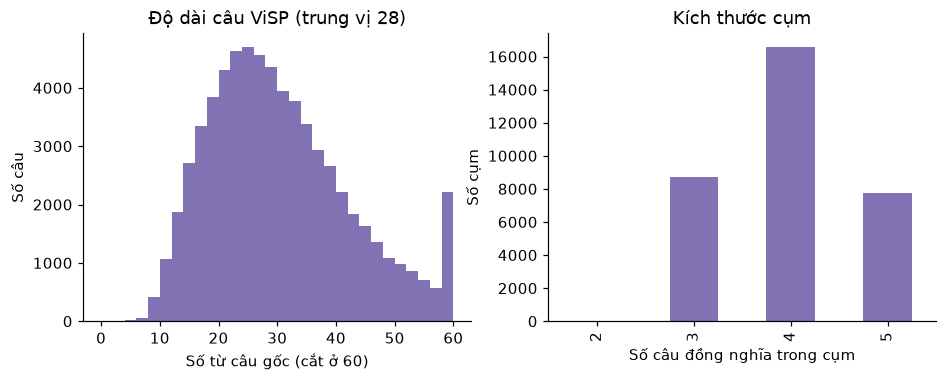

In [2]:
train = visp["train"]
cluster = train.groupby("group_id").references.first().map(len) + 1
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
lens = train.source.map(lambda s: len(tokenize(s))).clip(upper=60)
axes[0].hist(lens, bins=range(0, 62, 2), color=COLORS["visp"])
axes[0].set(xlabel="Số từ câu gốc (cắt ở 60)", ylabel="Số câu", title=f"Độ dài câu ViSP (trung vị {int(lens.median())})")
cluster.value_counts().sort_index().plot.bar(ax=axes[1], color=COLORS["visp"])
axes[1].set(xlabel="Số câu đồng nghĩa trong cụm", ylabel="Số cụm", title="Kích thước cụm")
fig.savefig(FIG / "02_visp_length_cluster.png")

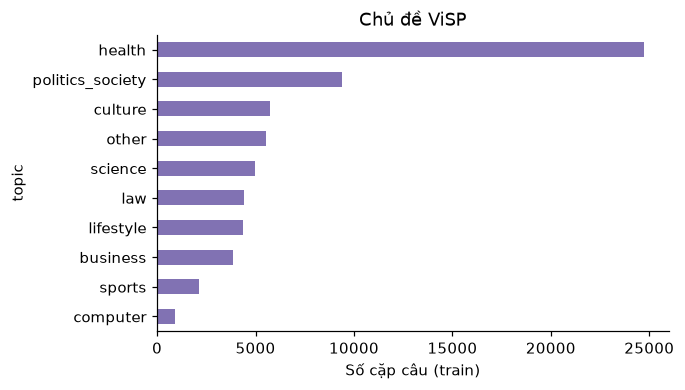

In [3]:
topics = train.topic.value_counts()
ax = topics.sort_values().plot.barh(figsize=(6, 3.5), color=COLORS["visp"])
ax.set(xlabel="Số cặp câu (train)", title="Chủ đề ViSP")
ax.figure.savefig(FIG / "02_visp_topics.png")

## Câu người viết giống câu gốc đến mức nào?

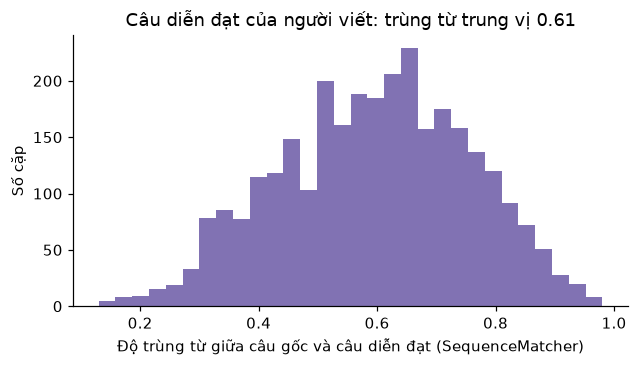

In [4]:
sample = visp["test"].sample(3000, random_state=0)
ov = [word_overlap(s, t) for s, t in zip(sample.source, sample.target)]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(ov, bins=30, color=COLORS["visp"])
ax.set(xlabel="Độ trùng từ giữa câu gốc và câu diễn đạt (SequenceMatcher)", ylabel="Số cặp",
       title=f"Câu diễn đạt của người viết: trùng từ trung vị {pd.Series(ov).median():.2f}")
fig.savefig(FIG / "02_visp_overlap.png")

In [5]:
def load(name):
    return json.loads(Path(f"outputs/metrics/{name}.json").read_text(encoding="utf-8"))
rows = {"Chép câu gốc": load("paraphrase_visp_test_baseline_copy_n2000"),
        "Câu người viết (1 tham chiếu)": load("paraphrase_visp_test_baseline_target_n2000"),
        "ViT5-base fine-tune": load("paraphrase_visp_test_vit5-base_n2000")}
ep4 = Path("outputs/metrics/paraphrase_visp_test_vit5-base-ep4_n2000.json")
if ep4.exists():
    rows["ViT5-base fine-tune (+2 epoch)"] = load("paraphrase_visp_test_vit5-base-ep4_n2000")
cols = ["bleu_ref", "self_bleu", "ibleu", "distinct_2", "semantic_sim_to_source"]
table = pd.DataFrame(rows).T.reindex(columns=cols)
table.to_csv(TAB / "02_paraphrase_baselines.csv")
table.style.format("{:.3f}", na_rep="–")

,bleu_ref,self_bleu,ibleu,distinct_2,semantic_sim_to_source
Chép câu gốc,76.033,100.000,40.826,0.549,1.000
Câu người viết (1 tham chiếu),73.878,47.902,49.522,0.546,0.921
ViT5-base fine-tune,75.919,74.159,45.903,0.540,0.968
ViT5-base fine-tune (+2 epoch),73.894,68.823,45.351,0.544,0.958


Chép nguyên câu gốc đạt BLEU cao hơn câu do người viết, nên BLEU/độ tương đồng không đủ để đánh giá diễn đạt lại; cần thêm self-BLEU (thấp = khác câu gốc), NLI và chấm thủ công.